In [ ]:
# Task 2
# Imports
import numpy as np
import matplotlib.pyplot as plt
import random

array([[  3300, 100000],
       [  6964,  10483],
       [  -681,   3407],
       ...,
       [  6619,  11030],
       [  3651,   7391],
       [ 12340,  18087]], shape=(1001, 2))

[ 3300  6964  -681 ...  6619  3651 12340]
[100000  10483   3407 ...  11030   7391  18087]
=== Max Values ===
17195
100000
=== Min Values ===
-4299
1
=== Mean Values ===
5762.1738261738265
10134.013986013986


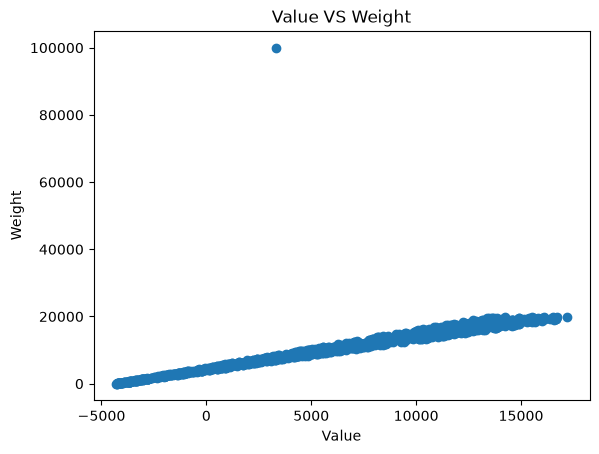

In [2]:
# 1
dataArr = np.genfromtxt("../data/data_1001.csv",
                    delimiter=",", dtype=int, skip_header=1)
display(dataArr)
item_values = dataArr[:, 0] # first column
item_weights = dataArr[:, 1] # second column

print(item_values)
print(item_weights)

print("=== Max Values ===")
print(item_values.max())
print(item_weights.max())

print("=== Min Values ===")
print(item_values.min())
print(item_weights.min())

print("=== Mean Values ===")
print(item_values.mean())
print(item_weights.mean())

plt.scatter(item_values, item_weights)
plt.title("Value VS Weight")
plt.xlabel("Value")
plt.ylabel("Weight")
plt.show()

In [3]:
# 2 Initialization
def initialization_population( pop_size: int, num_bits: int=1001  ) -> list[list[int]]:
    """
    This function creates the individuals for the population, each having 1001 binary genes. 

    It returns the individuals as a list of lists e.g., [[0, 1, 1, 0, 1,0], [0, 1, 1, 1, 1,1]].
    """
    population = []
    for _ in range(pop_size):
        population.append(np.random.randint(0, 2, num_bits, int).tolist()) # individual (1001 binary string)
    return population

In [4]:
# 3 Fitness 
def fitness_knapsack(individuals):
    return [np.dot(individual, item_values) for individual in individuals]


In [ ]:
# 4 SGA
# Parents
def parent_selection( individuals: list[list[int]], fitness_values: list[float] ) -> list[list[int]]:
    """Perform fitness-proportional parent selection such that more fit parents have a higher probability to be selected. """
    fitness_values = np.array(fitness_values, dtype=float)
    shifted = fitness_values - fitness_values.min() + 1
    fitness = np.array(shifted, dtype=float)
    probs = fitness / fitness.sum()
    idx = np.random.choice(len(individuals), size=len(individuals), replace=True, p=probs)
    return [individuals[i] for i in idx]

# Crossover
def one_point_crossover( parents: list[list[int]], crossover_prob: float ) -> list[list[int]]:
    """Performs 1-point crossover and generates for parents 1 & 2, parents 3 & 4 etc. offspring. """
    offsprings = []
    for i in range(0, len(parents)-1, 2):
        parent1, parent2 = parents[i], parents[i+1]
        offspring1, offspring2 = parent1.copy(), parent2.copy()

        alpha = np.random.uniform(0, 1)
        if alpha <= crossover_prob:
            cpoint = random.randint(1, len(parent1) - 1)
            offspring1 = parent1[:cpoint] + parent2[cpoint:]
            offspring2 = parent2[:cpoint] + parent1[cpoint:]

        offsprings.append(offspring1)
        offsprings.append(offspring2)

    if len(parents) % 2 == 1:
        offsprings.append(parents[-1].copy())

    return offsprings

# Mutation
def mutation( individuals: list[list[int]], mutation_prob: float ) -> list[list[int]]:
    """Performs bitflip mutation for each bit / gene in each individual with mutation probability of P_M."""
    mutated = []
    for individual in individuals:
        offspring = individual.copy()
        for i in range(len(offspring)):
            if np.random.uniform(0, 1) <= mutation_prob:
                offspring[i] = 1 - individual[i] # flipping each bit
            else:
                continue
        mutated.append(offspring)
    return mutated

# Survivor selection
def survivor_selection( individuals: list[list[int]], offspring: list[list[int]],
                        fitness_individuals: list[float], fitness_offspring: list[float]) -> list[list[int]]:
    """Selects survivors based on the highest fitness values from the pooled population individuals and offspring. """
    combined = individuals + offspring
    combined_fitness = fitness_individuals + fitness_offspring
    fitness_ordered = np.argsort(combined_fitness)[::-1]

    return  [combined[i] for i in fitness_ordered[:len(individuals)]]

def display_generation_fitness( new_avg_fit: float, new_best_fit: float, iter: int ):    
    print(f"Generation {iter:_}")
    print("-" * 50)
    print(f"Avg. fit: {new_avg_fit:_.6f} | Best fit: {new_best_fit:_.6f}") 
    print("-" * 50 + "\n")

def simple_genetic_algorithm( params: dict[str, int | float] ):
    """Complete version of the simple genetic algorithm (SGA).
    
    params:
        1. n_pop: Controls the population size.
        2. n_bits: Defines the number of bits in a single candidate solution.
        3. c_prob: Probability that crossover (recombination) occurs between parent chromosomes.
        4. m_prob: Determines how frequently random changes occur in the offspring.
        5. n_iter: Termination criteria. Fixed number of algorithm iterations or generations to produce.
    """
    avg_fitness_data, best_fitness_data = [], []

    population = initialization_population( params["n_pop"], params["n_bits"] )
    curr_avg_fit, curr_best_fit = 0.0, 0.0
    best_individual = None

    for _ in range( params["n_iter"] ):
        fitness_values = fitness_knapsack(population)

        new_avg_fit, new_best_fit = np.mean(fitness_values), np.max(fitness_values)
        # display_generation_fitness( new_avg_fit, new_best_fit, i + 1 )
        
        avg_fitness_data.append( new_avg_fit )
        best_fitness_data.append( new_best_fit )
        

        if new_best_fit > curr_best_fit:
            curr_best_fit = new_best_fit
            best_individual = population[np.argmax(fitness_values)]

        if new_avg_fit > curr_avg_fit:
            curr_avg_fit = new_avg_fit
        
        parents = parent_selection(population, fitness_values)
        offspring = one_point_crossover( parents, params["c_prob"] )
        offspring = mutation(offspring, params["m_prob"])
        survivors = survivor_selection(population, offspring, fitness_values, fitness_knapsack(offspring))    

        population = survivors

    return avg_fitness_data, best_fitness_data, best_individual

avgFitness, bestFitness, bestIndividual = simple_genetic_algorithm({ "n_pop": 30, "n_bits": 1001, "c_prob": 0.9, "m_prob": 0.1, "n_iter": 1000 })
print(avgFitness)
print(bestFitness)
print(bestIndividual)

[np.float64(2914318.8333333335), np.float64(3019794.3), np.float64(3104584.8), np.float64(3168352.1666666665), np.float64(3233615.966666667), np.float64(3280426.966666667), np.float64(3320479.8), np.float64(3340412.3333333335), np.float64(3363986.7), np.float64(3389505.4), np.float64(3404783.3), np.float64(3417165.9), np.float64(3425037.3), np.float64(3436983.9), np.float64(3446047.933333333), np.float64(3455811.966666667), np.float64(3466369.2333333334), np.float64(3485752.7), np.float64(3503336.933333333), np.float64(3530044.0), np.float64(3571698.966666667), np.float64(3584326.6333333333), np.float64(3603310.033333333), np.float64(3619502.6333333333), np.float64(3632692.8), np.float64(3645176.8666666667), np.float64(3656622.3333333335), np.float64(3665278.6), np.float64(3671865.7666666666), np.float64(3678434.0), np.float64(3684626.033333333), np.float64(3685949.8333333335), np.float64(3687747.1666666665), np.float64(3689486.2666666666), np.float64(3695862.4), np.float64(3695862.4),

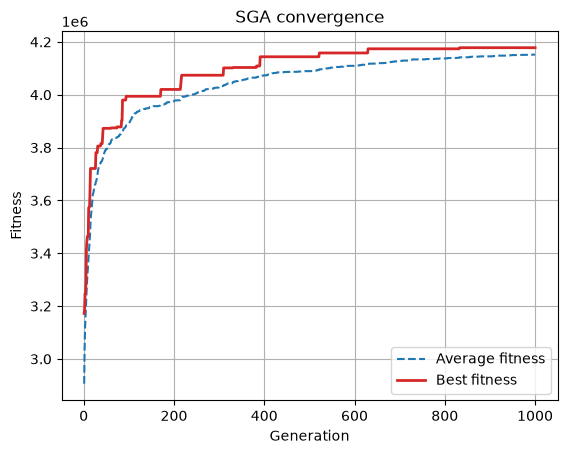

Final avg fitness: 4192372.50
Final best fitness: 4269355
Items selected: 621


In [12]:
# 5
def plot_fitness_data( avg_fitness_data: list[float], best_fitness_data: list[float], num_iter: int ):
    gens = range(1, num_iter + 1)
    plt.plot(gens, avg_fitness_data, color="tab:blue", linestyle="--", label="Average fitness")
    plt.plot(gens, best_fitness_data, color="tab:red",  linestyle="-",  linewidth=2, label="Best fitness")
    plt.xlabel("Generation")
    plt.ylabel("Fitness")
    plt.title("SGA convergence")
    plt.legend()
    plt.grid(True)
    plt.show()

def sga_trial( params: dict[str, int | float ]):
    avg_fitness_data, best_fitness_data, best_individual  = simple_genetic_algorithm( params )
    plot_fitness_data( avg_fitness_data, best_fitness_data, params["n_iter"] )

sga_trial( { "n_pop": 30, "n_bits": 1001, "c_prob": 0.9, "m_prob": 0.1, "n_iter": 1000 } )

print(f"Final avg fitness: {avgFitness[-1]:.2f}")
print(f"Final best fitness: {bestFitness[-1]}")
print(f"Items selected: {sum(bestIndividual)}")

In [11]:
selected = np.array(bestIndividual) == 1
not_selected = ~selected

sel_values = item_values[selected]
sel_weights = item_weights[selected]
sel_ratio = sel_values / sel_weights
print("=== Selected Individuals ===")
print("=== Selected Values Min, Max and Mean ===")
print(sel_values.min())
print(sel_values.max())
print(sel_values.mean())
print("=== Selected Weights Min, Max and Mean ===")
print(sel_weights.min())
print(sel_weights.max())
print(sel_weights.mean())
print("=== Selected Ratio Min, Max and Mean ===")
print(sel_ratio.min())
print(sel_ratio.max())
print(sel_ratio.mean())

non_sel_values = item_values[not_selected]
non_sel_weights = item_weights[not_selected]
non_sel_ratio = non_sel_values / non_sel_weights
print("=== Non Selected Individuals")
print("=== Non Selected Values Min, Max and Mean ===")
print(non_sel_values.min())
print(non_sel_values.max())
print(non_sel_values.mean())
print("=== Non Selected Weights Min, Max and Mean ===")
print(non_sel_weights.min())
print(non_sel_weights.max())
print(non_sel_weights.mean())
print("=== Non Selected Ratio Min, Max and Mean ===")
print(non_sel_ratio.min())
print(non_sel_ratio.max())
print(non_sel_ratio.mean())

=== Selected Individuals ===
=== Selected Values Min, Max and Mean ===
-4262
17195
6874.967793880837
=== Selected Weights Min, Max and Mean ===
38
100000
11301.834138486312
=== Selected Ratio Min, Max and Mean ===
-112.15789473684211
0.8689629939368597
-0.24691351985604607
=== Non Selected Individuals
=== Non Selected Values Min, Max and Mean ===
-4299
16688
3943.6342105263157
=== Non Selected Weights Min, Max and Mean ===
1
19644
8225.55
=== Non Selected Ratio Min, Max and Mean ===
-4299.0
0.8646184135537018
-12.50263926033968
